# Progress Report 2: Regression

**CS 4330 – Data Science**

**Dr. Dogdu**
  
Eryna Plong  
Bunlong Tan  
Tanner Love  

### Setup

**Libraries and data folder:** the first cell imports the libraries and finds the data folder. On Colab it uses the shared Google Drive folder, and when run locally it uses ../dataset.

In [1]:
#==============================================================
#=========== DO NOT MODIFY THIS CODE CELL =====================
#==============================================================

import glob, pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, accuracy_score, recall_score, classification_report, mean_squared_error

try:
    # Colab: read the data from the shared Google Drive folder
    from google.colab import drive
    drive.mount('/content/drive')
    DATA = (glob.glob('/content/drive/*/vulngraph-gnn/dataset') + glob.glob('/content/drive/*/*/vulngraph-gnn/dataset'))[0]
except ImportError:
    # Local: the dataset folder sits next to this notebook's folder in the repo
    DATA = '../dataset'

U = f'{DATA}/uckg' # U for UCKG
print('Using', DATA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using /content/drive/MyDrive/vulngraph-gnn/dataset


**Loading the data:** the next cell reads the NVD table (one row per CVE) and the knowledge graph's node and edge tables from the uckg folder.

In [2]:
#==============================================================
#=========== DO NOT MODIFY THIS CODE CELL =====================
#==============================================================

# --- Main table: one row per CVE (label = severity or base_score) # parse_dates=['published', 'last_modified'] converts to real dates ---
nvd = pd.read_csv(f'{DATA}/nvd_cves.csv', parse_dates=['published', 'last_modified'], low_memory=False)

# --- Graph nodes ---
cwes   = pd.read_csv(f'{U}/cwes.csv')
capecs = pd.read_csv(f'{U}/capecs.csv')
attack = pd.read_csv(f'{U}/attack_techniques.csv')

# --- Graph edges ---
cve_cwe      = pd.read_csv(f'{U}/edges_cve_cwe.csv')
cve_cpe      = pd.read_csv(f'{U}/edges_cve_cpe.csv')
capec_cwe    = pd.read_csv(f'{U}/edges_capec_cwe.csv')
capec_attack = pd.read_csv(f'{U}/edges_capec_attack.csv')

**Building df:** the next cell combines the NVD table with four counts from the knowledge graph into one table, df. The steps are explained after the cell.

In [3]:
# --- Combined CVE-level table: NVD + graph counts ---
cve_capec  = cve_cwe.merge(capec_cwe, on='cwe_id')[['cve_id', 'capec_id']].drop_duplicates()
cve_attack = cve_capec.merge(capec_attack, on='capec_id')[['cve_id', 'attack_id']].drop_duplicates()

graph_feats = pd.DataFrame({
    'n_cwe':    cve_cwe.groupby('cve_id').size(),
    'n_cpe':    cve_cpe.groupby('cve_id').size(),
    'n_capec':  cve_capec.groupby('cve_id').size(),
    'n_attack': cve_attack.groupby('cve_id').size(),
})

df = nvd.merge(graph_feats, left_on='cve_id', right_index=True, how='left')
df[graph_feats.columns] = df[graph_feats.columns].fillna(0).astype(int)

# Keep only CVEs that have a v3 label
df = df[df['severity'].notna() & (df['severity'] != 'NONE')]

"df" is the main table for modeling. It has one row per CVE: all the NVD columns plus four counts taken from the knowledge graph.

In [4]:
# df is the main data frame and can be seen below
print(f'\n=== df  {df.shape} ===')
display(df.head())


=== df  (307239, 32) ===


,cve_id,published,last_modified,vuln_status,description,cvss3_version,cvss3_source,base_score,severity,vector_string,...,cvss4_base_score,cvss4_severity,cwe,all_cwes,vendors,products,n_cwe,n_cpe,n_capec,n_attack
6,CVE-1999-0084,1990-05-01 04:00:00,2026-06-16 21:47:32.553,Modified,Certain NFS servers allow users to use mknod t...,3.1,Secondary,8.4,HIGH,CVSS:3.1/AV:L/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-269,CWE-269,sun,sun:nfs,1,1,3,1
92,CVE-1999-0066,1995-07-31 04:00:00,2026-06-16 21:47:29.853,Modified,AnyForm CGI remote execution.,3.1,Secondary,9.8,CRITICAL,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,NaN,NaN,john_s._roberts,john_s._roberts:anyform,0,1,0,0
130,CVE-1999-0022,1996-07-03 04:00:00,2026-06-16 21:47:22.167,Modified,Local user gains root privileges via buffer ov...,3.1,Secondary,7.8,HIGH,CVSS:3.1/AV:L/AC:L/PR:L/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-125,CWE-125,bsdi;freebsd;hp;ibm;sgi;sun,bsdi:bsd_os;freebsd:freebsd;hp:hp-ux;ibm:aix;s...,1,2,1,0
171,CVE-1999-0043,1996-12-04 05:00:00,2026-06-16 21:47:26.437,Modified,Command execution via shell metachars in INN d...,3.1,Secondary,9.8,CRITICAL,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-78,CWE-78,bsdi;caldera;isc;nec;netscape;redhat,bsdi:bsd_os;caldera:openlinux;isc:inn;nec:goah...,1,3,5,0
197,CVE-1999-0236,1997-01-01 05:00:00,2026-06-16 21:47:58.393,Modified,ScriptAlias directory in NCSA and Apache httpd...,3.1,Primary,7.5,HIGH,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:N/A:N,...,NaN,NaN,NaN,NaN,apache;illinois,apache:http_server;illinois:ncsa_httpd,0,1,0,0


### (1) Linear Regression
In this section we build a simple linear regression model that uses one attribute to predict another. We use **impact_score** to predict **base_score**. We chose this pair because it had the strongest correlation **(0.84)** in the heatmap from Progress Report 1, so a straight line should fit it well.

**Choosing the attributes:** X is the attribute the model learns from (impact_score), and y is the attribute it predicts (base_score). X uses double brackets because sklearn expects X to be a table, even with one column.

In [5]:
# X = the input attribute, y = the attribute we want to predict
X_s = df[["impact_score"]]
y_s = df["base_score"]

print("X shape:", X_s.shape)
print("y shape:", y_s.shape)

X shape: (307239, 1)
y shape: (307239,)


X has 307,239 rows and 1 column (impact_score), and y has the same 307,239 values (base_score), so every CVE has both an input and an answer.

**Splitting the data:** we train the model on 80% of the CVEs and keep 20% for testing. Testing on CVEs the model has never seen shows whether it really learned the pattern. random_state=42 makes the split the same every time the notebook runs.

In [6]:
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

print("Training rows:", len(X_train_s))
print("Testing rows: ", len(X_test_s))

Training rows: 245791
Testing rows:  61448


The model will learn from 245,791 CVEs (80%) and be tested on 61,448 CVEs (20%) that it has never seen.


**Training the model:** LinearRegression finds the straight line that best fits the training data. Then we use it to predict the base score of every CVE in the test set.

In [7]:
simple_lr = LinearRegression()
simple_lr.fit(X_train_s, y_train_s)

y_pred_s = simple_lr.predict(X_test_s)

**Measuring performance:** R² shows how much of the variation in base_score the model explains (1 is perfect). MSE is the average squared difference between the predicted and real scores (lower is better). The slope and intercept describe the fitted line.

In [8]:
r2_s = r2_score(y_test_s, y_pred_s)
mse_s = mean_squared_error(y_test_s, y_pred_s)

print("--- Linear Regression Performance ---")
print(f"R² Score: {r2_s:.4f}")
print(f"Mean Squared Error (MSE): {mse_s:.4f}")
print(f"Slope: {simple_lr.coef_[0]:.4f}")
print(f"Intercept: {simple_lr.intercept_:.4f}")

--- Linear Regression Performance ---
R² Score: 0.7094
Mean Squared Error (MSE): 0.8321
Slope: 0.9238
Intercept: 3.1510


**Observed vs. predicted plot:** the blue dots are the real base scores and the red line is the model's predictions. We plot a random sample of 2,000 test CVEs, because all 61,000 would cover the plot in one blob.

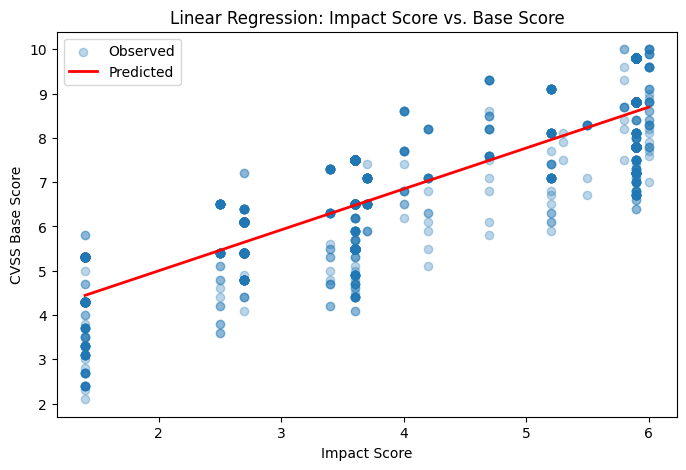

In [9]:
# Random sample of the test set so the plot stays readable
plot_idx = X_test_s.sample(2000, random_state=42).index

# Points along the x-axis to draw the prediction line
line_x = pd.DataFrame({"impact_score": np.linspace(X_s["impact_score"].min(), X_s["impact_score"].max(), 100)})
line_y = simple_lr.predict(line_x)

plt.figure(figsize=(8, 5))
plt.scatter(X_test_s.loc[plot_idx, "impact_score"], y_test_s.loc[plot_idx],
            alpha=0.3, label="Observed")
plt.plot(line_x["impact_score"], line_y, color="red", linewidth=2, label="Predicted")
plt.title("Linear Regression: Impact Score vs. Base Score")
plt.xlabel("Impact Score")
plt.ylabel("CVSS Base Score")
plt.legend()
plt.show()

**Results:** The model has an R² of 0.7094, which means impact_score alone explains about 71% of the variation in base_score. This is high for a model with only one input. The MSE is 0.8321, so the predictions are off by about 0.9 points on average (the square root of the MSE) on the 0 to 10 scale. The slope of 0.9238 means that each 1-point increase in impact score raises the predicted base score by about 0.92 points, starting from an intercept of 3.15.

In the plot, the dots form vertical stripes because impact_score can only take certain values, such as 1.4, 3.6, and 5.9. The red line rises through the middle of each stripe, so the predictions follow the real scores closely. Each stripe still spreads over about 3 to 4 points, because CVEs with the same impact score can have very different exploitability scores, which this model does not use. The strong fit makes sense because base_score is partly calculated from impact_score.

### (2) Multiple Linear Regression
**Choosing the attributes:** this model predicts **base_score** from four attributes: the two CVSS sub-scores, **exploitability_score** and **impact_score**, plus two knowledge-graph counts, **n_cpe** (number of affected products) and **n_attack** (number of linked ATT&CK techniques).

The cell splits the data 80/20 as in Part 1, trains `LinearRegression`, prints R², MSE and the coefficients, and draws a 3D plot with **mplot3d**. Exploitability and impact are on the two flat axes and base score goes up; blue points are observed and red points are predicted.

--- Multiple Linear Regression Performance ---
R² Score: 0.9867
Mean Squared Error (MSE): 0.0381
Model Coefficients:
  exploitability_score: 0.9584
  impact_score: 0.9695
  n_cpe: -0.0003
  n_attack: -0.0041
Intercept: 0.4058


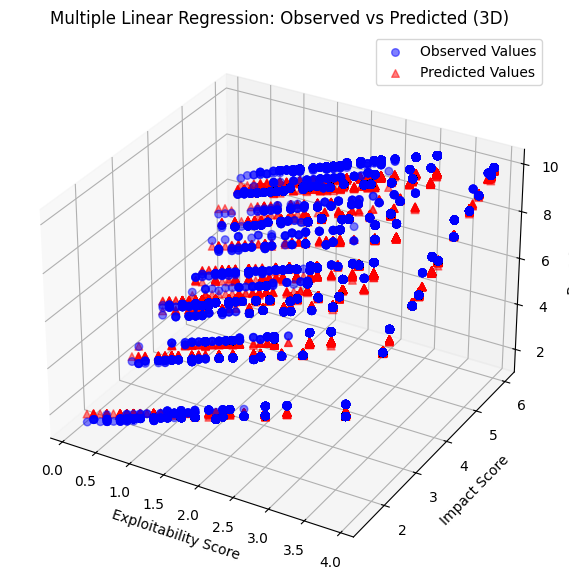

In [10]:
## Some of these are similar to zyBooks since they were shown in class ##
from mpl_toolkits.mplot3d import Axes3D  # mplot3d: adds the 3D projection used in the plot below

# Select more than two independent attributes and a target variable
feature_cols = ['exploitability_score', 'impact_score', 'n_cpe', 'n_attack'] # identify
target_col = 'base_score'

# Input + Predict the CVSS Score
X_multi = df[feature_cols]
y_multi = df[target_col]

# Split data into training (80%) and testing (20%) sets
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

# Initialize and train the Multiple Linear Regression
multi_lr = LinearRegression()
multi_lr.fit(X_train_m, y_train_m)

# Generate predictions on the test set
y_pred_m = multi_lr.predict(X_test_m)

# Measure model performance
r2_m = r2_score(y_test_m, y_pred_m) # R²: share of the variation in base_score the model explains
mse_m = mean_squared_error(y_test_m, y_pred_m) # test the MSE

print("--- Multiple Linear Regression Performance ---")
print(f"R² Score: {r2_m:.4f}")
print(f"Mean Squared Error (MSE): {mse_m:.4f}")
print("Model Coefficients:")
for col, coef in zip(feature_cols, multi_lr.coef_):
    print(f"  {col}: {coef:.4f}")
print(f"Intercept: {multi_lr.intercept_:.4f}")

# Draw a 3D plot using mplot3d to display observed vs predicted values
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Plot actual observed test points (using exploitability and impact for X and Y axes, and base score for Z)
ax.scatter(X_test_m['exploitability_score'], X_test_m['impact_score'], y_test_m,
           color='blue', label='Observed Values', alpha=0.5, s=30)

# Plot predicted points
ax.scatter(X_test_m['exploitability_score'], X_test_m['impact_score'], y_pred_m,
           color='red', label='Predicted Values', alpha=0.5, marker='^', s=30)

ax.set_xlabel('Exploitability Score')
ax.set_ylabel('Impact Score')
ax.set_zlabel('Base Score')
ax.set_title('Multiple Linear Regression: Observed vs Predicted (3D)')
plt.legend()
plt.show()


**Results:** R² rises from 0.71 in Part 1 to **0.987**, and MSE drops from 0.83 to 0.038, so predictions are off by about 0.2 points. Almost all of the gain comes from adding **exploitability_score**: its coefficient (0.96) is about the same as impact_score's (0.97). The graph counts add almost nothing, with **n_cpe** at −0.0003 and **n_attack** at −0.0041.

The fit is nearly perfect because the CVSS formula calculates base_score from the impact and exploitability sub-scores, roughly by adding them, so a linear model can almost rebuild it. In the 3D plot the red predicted points sit right on top of the blue observed points. The small gaps come from the formula's rounding and its extra rule for CVEs with a changed scope.

### (3) Logistic Regression: predicting severe CVEs before NVD scores them

**Target:** 1 = HIGH/CRITICAL (base score ≥ 7.0), 0 = LOW/MEDIUM.
- **3a:** a ceiling model built from the 8 CVSS metrics an analyst assigns.
- **3b:** a publication-time model built from the description text and knowledge-graph links.
- **3c:** what the 3b model learned.

This cell removes two label leaks from the text. It drops 7,832 Oracle CVEs whose description states the CVSS score, and it strips the "(Chromium security severity: …)" tag. It then builds the 0/1 target and splits by year: train on ≤2024, test on 2025–26. This mirrors real use, where the model learns from the past and predicts new CVEs.

In [11]:
# Extra tools for Part 3 (the setup cell at the top must not be modified)
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score, f1_score, ConfusionMatrixDisplay

# Remove label leaks hidden in the text: Oracle descriptions state the CVSS score and impacts,
# and Chromium descriptions end with the vendor's own severity rating
def clean_descriptions(frame):
    oracle = frame['description'].str.contains(r'CVSS 3\.\d Base Score|(?:Easily|Difficult) to exploit vulnerability', na=False)
    frame = frame[~oracle].copy()
    frame['description'] = frame['description'].fillna('').str.replace(r'\(Chromium security severity: \w+\)', '', regex=True)
    return frame.reset_index(drop=True), oracle.sum()

lr_df, n_oracle = clean_descriptions(df)
print(f'Dropped {n_oracle:,} Oracle CVEs whose description contains the CVSS score')

# Target: 1 = HIGH or CRITICAL, 0 = LOW or MEDIUM
y_bin = lr_df['severity'].isin(['HIGH', 'CRITICAL']).astype(int).values

# Temporal split: learn from the past, test on the "future"
train_mask = (lr_df['published'].dt.year <= 2024).values
test_mask = ~train_mask
y_tr, y_te = y_bin[train_mask], y_bin[test_mask]

print(f'Train (published 2024 or earlier): {train_mask.sum():,} CVEs, {y_tr.mean():.1%} HIGH/CRITICAL')
print(f'Test  (published 2025-2026):       {test_mask.sum():,} CVEs, {y_te.mean():.1%} HIGH/CRITICAL')

def report(name, y_true, p):
    """Accuracy, F1 and ROC-AUC for a vector of predicted probabilities p."""
    return {'model': name,
            'accuracy': accuracy_score(y_true, p >= 0.5),
            'f1': f1_score(y_true, p >= 0.5),
            'roc_auc': roc_auc_score(y_true, p)}

Dropped 7,832 Oracle CVEs whose description contains the CVSS score
Train (published 2024 or earlier): 183,542 CVEs, 56.0% HIGH/CRITICAL
Test  (published 2025-2026):       115,865 CVEs, 53.3% HIGH/CRITICAL


Both sets are about 55% HIGH/CRITICAL. Always guessing HIGH/CRITICAL would score 53% on the test set, and that is the baseline to beat.

#### 3a – Ceiling model: the 8 CVSS metrics
Each metric level (e.g. `attack_vector=NETWORK`) is one-hot encoded and fed to `LogisticRegression`.

In [12]:
cvss_cols = ['attack_vector', 'attack_complexity', 'privileges_required', 'user_interaction',
             'scope', 'confidentiality_impact', 'integrity_impact', 'availability_impact']

# One 0/1 column per metric level, e.g. attack_vector=NETWORK
X_cvss = pd.get_dummies(lr_df[cvss_cols], prefix_sep='=').astype(float)

ceiling_lr = LogisticRegression(max_iter=2000)
ceiling_lr.fit(X_cvss[train_mask], y_tr)
p_ceiling = ceiling_lr.predict_proba(X_cvss[test_mask])[:, 1]

res_ceiling = report('3a: 8 CVSS metrics', y_te, p_ceiling)
print(f"Accuracy: {res_ceiling['accuracy']:.4f}   F1: {res_ceiling['f1']:.4f}   ROC-AUC: {res_ceiling['roc_auc']:.4f}\n")
print(classification_report(y_te, (p_ceiling >= 0.5).astype(int),
                            target_names=['LOW/MEDIUM', 'HIGH/CRITICAL'], digits=3))

Accuracy: 0.9861   F1: 0.9869   ROC-AUC: 0.9968

               precision    recall  f1-score   support

   LOW/MEDIUM      0.978     0.992     0.985     54158
HIGH/CRITICAL      0.993     0.981     0.987     61707

     accuracy                          0.986    115865
    macro avg      0.986     0.987     0.986    115865
 weighted avg      0.986     0.986     0.986    115865



**98.6% accuracy, 0.997 ROC-AUC.** The few errors sit near the 7.0 cut-off, where the multiplicative CVSS formula and the additive logistic model disagree.

The plot shows each test CVE's log-odds against its observed label (jittered), the predicted-probability sigmoid, and the confusion matrix.

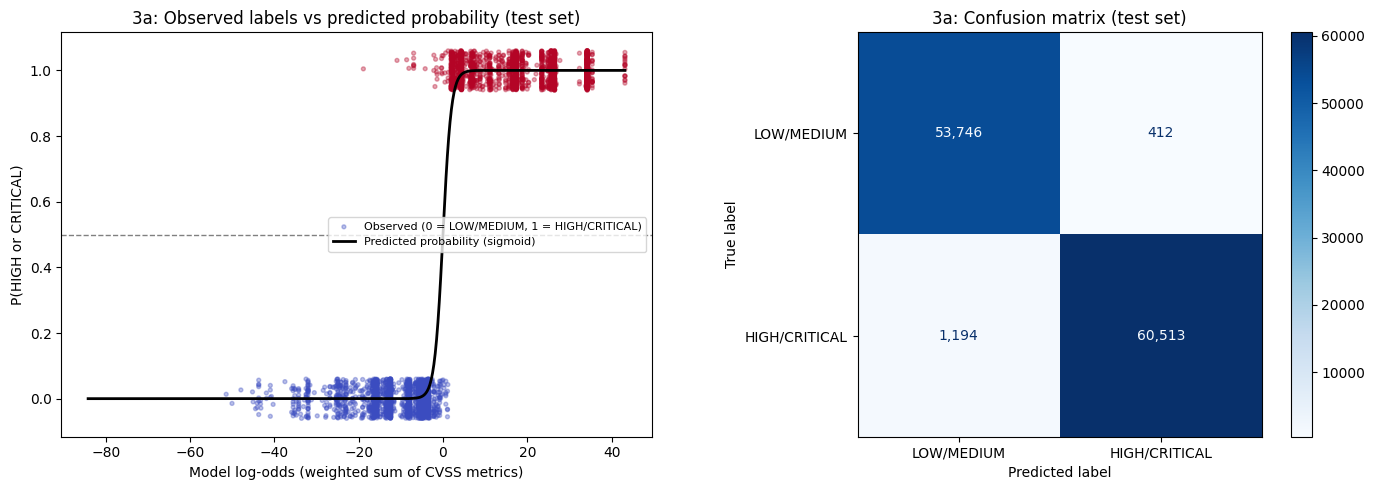

In [13]:
z_te = ceiling_lr.decision_function(X_cvss[test_mask])   # log-odds for each test CVE
rng = np.random.default_rng(42)
sample = rng.choice(len(z_te), 4000, replace=False)     # 4,000 points keep the plot readable

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
jitter = rng.uniform(-0.06, 0.06, len(sample))
ax.scatter(z_te[sample], y_te[sample] + jitter, c=y_te[sample], cmap='coolwarm',
           s=8, alpha=0.35, label='Observed (0 = LOW/MEDIUM, 1 = HIGH/CRITICAL)')
zz = np.linspace(z_te.min(), z_te.max(), 400)
ax.plot(zz, 1 / (1 + np.exp(-zz)), color='black', lw=2, label='Predicted probability (sigmoid)')
ax.axhline(0.5, color='gray', ls='--', lw=1)
ax.set_xlabel('Model log-odds (weighted sum of CVSS metrics)')
ax.set_ylabel('P(HIGH or CRITICAL)')
ax.set_title('3a: Observed labels vs predicted probability (test set)')
ax.legend(loc='center right', fontsize=8)

ConfusionMatrixDisplay.from_predictions(y_te, (p_ceiling >= 0.5).astype(int), ax=axes[1],
                                        display_labels=['LOW/MEDIUM', 'HIGH/CRITICAL'],
                                        cmap='Blues', values_format=',')
axes[1].set_title('3a: Confusion matrix (test set)')
plt.tight_layout()
plt.show()

Observed 1s sit above the 0.5 line and observed 0s below it, so predicted and observed agree for almost every CVE. **Catch:** these metrics only exist *after* the CVE is scored, which motivates 3b.

#### 3b – Publication-time model: text + knowledge graph
- **Text:** TF-IDF of the description (1–2 word phrases, 50k features, fit on training CVEs only).
- **Graph links:** 0/1 columns for each UCKG node a CVE links to: CWE, CAPEC (via CWE), ATT&CK (via CAPEC) and vendor (from CPE). NVD adds CPE during analysis, so the vendor links are not truly publication-time.

In [14]:
# --- Text: TF-IDF of the description, vocabulary learned from training CVEs only ---
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=50000, sublinear_tf=True)
X_text_tr = tfidf.fit_transform(lr_df.loc[train_mask, 'description'].fillna(''))
X_text_te = tfidf.transform(lr_df.loc[test_mask, 'description'].fillna(''))

# --- Graph: which CWE, CAPEC, ATT&CK and vendor nodes each CVE links to in UCKG ---
cve_vendor = (cve_cpe.assign(vendor=cve_cpe['cpe'].str.split(':').str[3])
              [['cve_id', 'vendor']].drop_duplicates())
graph_links = {
    'CWE':    (cve_cwe[['cve_id', 'cwe_id']].drop_duplicates(), 'cwe_id'),
    'CAPEC':  (cve_capec, 'capec_id'),
    'ATT&CK': (cve_attack, 'attack_id'),
    'Vendor': (cve_vendor, 'vendor'),
}
graph_vocab = {kind: pd.Index(edges[col].unique()) for kind, (edges, col) in graph_links.items()}

def link_matrix(cve_ids, kind):
    """Sparse 0/1 matrix: row i, column j = 1 if CVE i links to node j of this kind."""
    edges, col = graph_links[kind]
    row_of = pd.Series(np.arange(len(cve_ids)), index=pd.Index(cve_ids))
    e = edges[edges['cve_id'].isin(row_of.index)]
    return sp.csr_matrix((np.ones(len(e)), (row_of[e['cve_id']].values, graph_vocab[kind].get_indexer(e[col]))),
                         shape=(len(cve_ids), len(graph_vocab[kind])))

B = {kind: link_matrix(lr_df['cve_id'].values, kind) for kind in graph_links}
X_graph = sp.hstack(list(B.values())).tocsr()
X_graph_tr, X_graph_te = X_graph[train_mask], X_graph[test_mask]

print('Text features: ', X_text_tr.shape[1])
for kind, M in B.items():
    print(f'{kind:7s} nodes: {M.shape[1]:6,}   CVEs with at least one link: {(M.getnnz(axis=1) > 0).mean():.1%}')

Text features:  50000
CWE     nodes:    766   CVEs with at least one link: 90.2%
CAPEC   nodes:    446   CVEs with at least one link: 73.1%
ATT&CK  nodes:    170   CVEs with at least one link: 29.1%
Vendor  nodes: 35,870   CVEs with at least one link: 79.8%


**Ablation:** this trains a text-only model and a text + graph model, and tests both on 2025–26.

In [15]:
feature_sets = {
    'Text only': (X_text_tr, X_text_te),
    'Text + graph links': (sp.hstack([X_text_tr, X_graph_tr]).tocsr(), sp.hstack([X_text_te, X_graph_te]).tocsr()),
}

models, probs, results = {}, {}, [res_ceiling]
for name, (Xtr, Xte) in feature_sets.items():
    m = LogisticRegression(C=2.0, solver='lbfgs', max_iter=1000)
    m.fit(Xtr, y_tr)
    models[name], probs[name] = m, m.predict_proba(Xte)[:, 1]
    results.append(report(name, y_te, probs[name]))

ablation = pd.DataFrame(results).set_index('model')
display(ablation.round(4))

,accuracy,f1,roc_auc
model,,,
3a: 8 CVSS metrics,0.9861,0.9869,0.9968
Text only,0.7445,0.7663,0.8289
Text + graph links,0.7532,0.7754,0.8342


- **Text alone:** 74.4% accuracy, 0.829 AUC. Most of the signal is in the description.
- **Text + graph:** 75.3%, 0.834 AUC.

**For the research:** the graph mostly repeats the text ("SQL injection" *is* CWE-89). The GCN planned in our proposal must beat 0.834 to justify the graph.

**Who scored the label?** Each label is either NVD's own score (Primary) or the score from the CNA that published the CVE (Secondary). The next cell splits the test results by scorer.

In [16]:
# Who assigned the label? Primary = NVD analyst, Secondary = the CNA that published the CVE
src = lr_df['cvss3_source'].map({'Primary': 'NVD', 'Secondary': 'CNA'})
print('Share of labels scored by NVD:  train', f"{(src[train_mask] == 'NVD').mean():.0%}", '  test', f"{(src[test_mask] == 'NVD').mean():.0%}")
best_name = 'Text + graph links'
by_scorer = pd.DataFrame([report(s, y_te[(src[test_mask] == s).values], probs[best_name][(src[test_mask] == s).values])
                          for s in ['NVD', 'CNA']]).set_index('model').rename_axis('test labels scored by')
display(by_scorer.round(4))

Share of labels scored by NVD:  train 88%   test 27%


,accuracy,f1,roc_auc
test labels scored by,,,
NVD,0.8075,0.8117,0.8893
CNA,0.7331,0.7633,0.8139


NVD scored **88% of training labels but only 27% of test labels**. Because of its backlog, most 2025–26 CVEs only carry the CNA's score. The model matches NVD labels 80.8% of the time (0.889 AUC) but CNA labels only 73.3% (0.814). It learned NVD's scoring habits, and CNAs score differently. In the raw NVD feeds, the two agree on HIGH/CRITICAL only about 77% of the time when both scored a CVE. So much of the drop on future CVEs comes from a change in *who labels them*, not from the model going stale.

The next cell retrains the text model on a random 80/20 split for comparison.

In [17]:
# Same text model, but trained/tested on a random 80/20 split instead of past -> future
idx_tr, idx_te = train_test_split(np.arange(len(lr_df)), test_size=0.2, random_state=42)
tfidf_rand = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=50000, sublinear_tf=True)
Xr_tr = tfidf_rand.fit_transform(lr_df['description'].iloc[idx_tr].fillna(''))
Xr_te = tfidf_rand.transform(lr_df['description'].iloc[idx_te].fillna(''))
rand_lr = LogisticRegression(C=2.0, solver='liblinear', max_iter=1000).fit(Xr_tr, y_bin[idx_tr])
res_random = report('Text only (random split)', y_bin[idx_te], rand_lr.predict_proba(Xr_te)[:, 1])
print(f"Random split:   accuracy {res_random['accuracy']:.4f}   ROC-AUC {res_random['roc_auc']:.4f}")
print(f"Temporal split: accuracy {ablation.loc['Text only', 'accuracy']:.4f}   ROC-AUC {ablation.loc['Text only', 'roc_auc']:.4f}")

Random split:   accuracy 0.8274   ROC-AUC 0.9077
Temporal split: accuracy 0.7445   ROC-AUC 0.8289


The random split scores **8 points higher** (82.7% vs 74.4%). Its test set has the same NVD/CNA label mix as training, plus near-duplicate descriptions and shared vendors. The temporal split is the honest number.

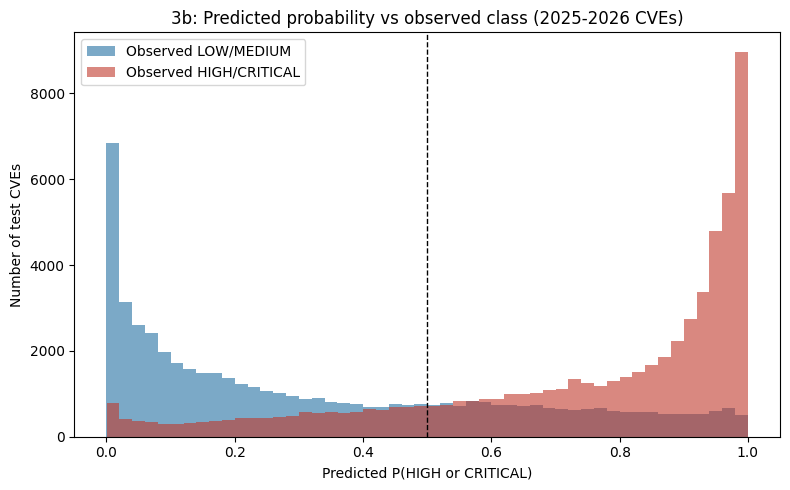

In [18]:
p_best = probs[best_name]

plt.figure(figsize=(8, 5))
plt.hist(p_best[y_te == 0], bins=50, alpha=0.6, color='#2471a3', label='Observed LOW/MEDIUM')
plt.hist(p_best[y_te == 1], bins=50, alpha=0.6, color='#c0392b', label='Observed HIGH/CRITICAL')
plt.axvline(0.5, color='black', ls='--', lw=1)
plt.xlabel('Predicted P(HIGH or CRITICAL)')
plt.ylabel('Number of test CVEs')
plt.title('3b: Predicted probability vs observed class (2025-2026 CVEs)')
plt.legend()
plt.tight_layout()
plt.show()

Predicted vs observed: the classes separate but overlap around 0.3–0.7, which covers the CVEs whose descriptions are ambiguous. The probabilities are somewhat overconfident at the extremes.

#### 3c – What the model learned
The largest description-word and CWE coefficients of the text + graph model.

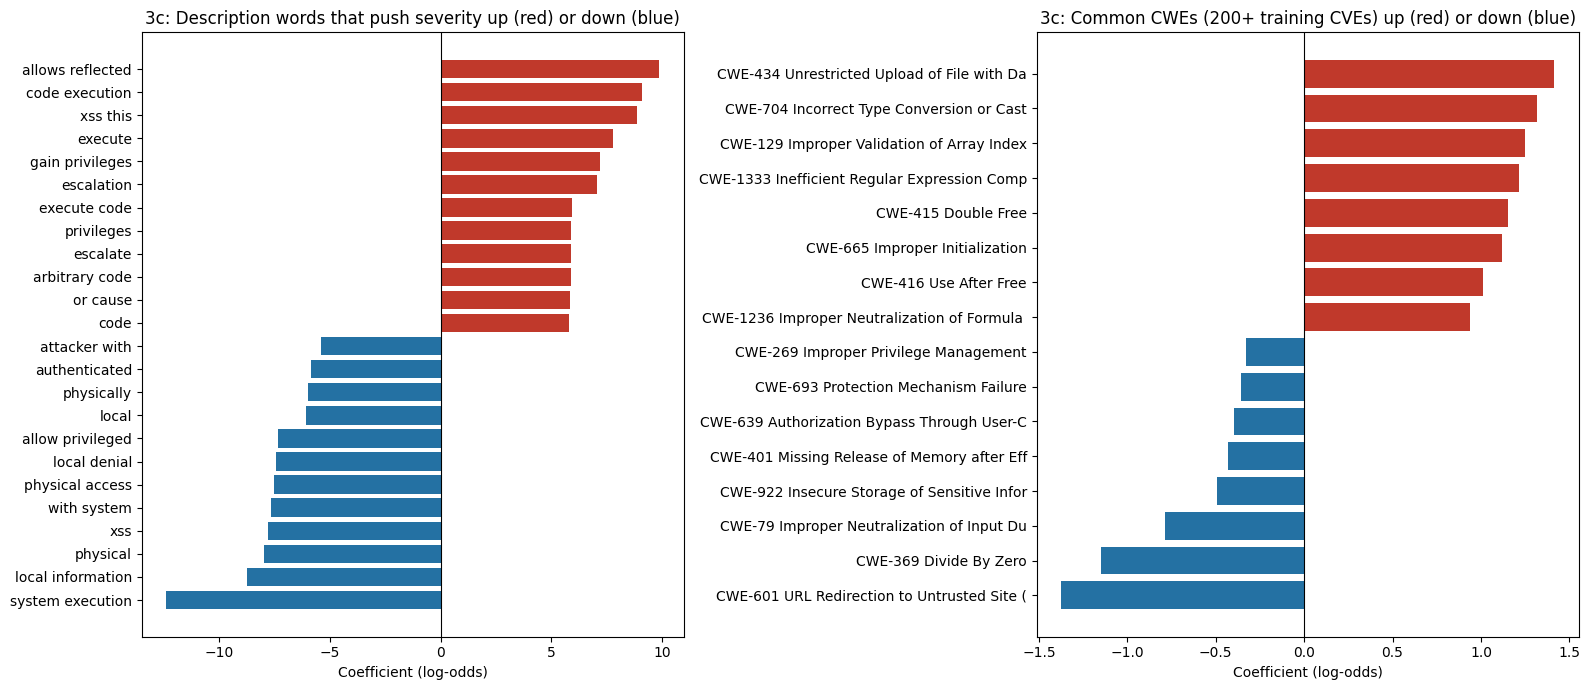

In [19]:
m = models[best_name]
names = np.concatenate([tfidf.get_feature_names_out()] +
                       [[f'{kind}: {v}' for v in graph_vocab[kind]] for kind in graph_links])
w = pd.Series(m.coef_[0], index=names)

text_w = w.iloc[:X_text_tr.shape[1]].sort_values()
# Only CWEs with at least 200 training CVEs, so the weights are not noise from rare CWEs
cwe_count = pd.Series(np.asarray(B['CWE'][train_mask].sum(axis=0)).ravel(), index=[f'CWE: {v}' for v in graph_vocab['CWE']])
cwe_w = w[cwe_count[cwe_count >= 200].index].sort_values()
cwe_names = cwes.set_index('cwe_id')['name']
cwe_w.index = [f"{c[5:]} {str(cwe_names.get(c[5:], ''))[:35]}" for c in cwe_w.index]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
top_text = pd.concat([text_w.head(12), text_w.tail(12)])
axes[0].barh(top_text.index, top_text.values, color=np.where(top_text.values > 0, '#c0392b', '#2471a3'))
axes[0].set_title('3c: Description words that push severity up (red) or down (blue)')
top_cwe = pd.concat([cwe_w.head(8), cwe_w.tail(8)])
axes[1].barh(top_cwe.index, top_cwe.values, color=np.where(top_cwe.values > 0, '#c0392b', '#2471a3'))
axes[1].set_title('3c: Common CWEs (200+ training CVEs) up (red) or down (blue)')
for ax in axes:
    ax.axvline(0, color='black', lw=0.8)
    ax.set_xlabel('Coefficient (log-odds)')
plt.tight_layout()
plt.show()

- **Severity Up:** code execution, arbitrary code, and gaining or escalating privileges.
- **Severity Down:** local or physical access, authenticated or privileged attackers, and XSS.
- **Overlapping phrases share weight**, so read the terms in groups. For example, "xss" is negative but "xss this" is positive.
- **Common CWEs:** file upload, use-after-free and double free push severity up; XSS (CWE-79), open redirect and divide-by-zero push it down.

**Part 3 summary:**
- Without the expert CVSS ratings, the model predicts severity on new CVEs at 75%, versus 98.6% with them.
- It matches NVD's labels 81% of the time but the CNAs' only 73%, and most new CVEs are CNA-scored.
- The knowledge graph adds almost nothing over the description, which sets the bar for the GCN planned in our proposal.

### Conclusion
- **Linear regression (1):** impact_score alone explains 71% of the variation in base_score (R² 0.71).
- **Multiple linear regression (2):** adding exploitability_score raises R² to 0.987, because the CVSS formula builds base_score from those two sub-scores. The graph counts added nothing.
- **Logistic regression (3):** the 8 CVSS metrics predict HIGH/CRITICAL with 98.6% accuracy. Using only what is known when a CVE is published (description and graph links), accuracy on 2025–26 CVEs is 75%.

**What we learned:**
- **High scores can mislead.** Parts 2 and 3a are near-perfect because their inputs are pieces of the score itself. Part 3b does the real test, predicting new CVEs from information available before scoring, and reaches 75%.
- **The split matters.** A random split made the text model look 8 points better than training on the past and testing on the future.
- **Labels depend on who scores.** NVD and the CNAs rate CVEs differently, and most new CVEs carry CNA scores, which explains much of the drop on future CVEs.
- **The graph adds little so far.** The description carries most of the signal. Our next models (Random Forest, XGBoost and the GCN) will test whether the graph structure can add more.